# 05 · Evaluation: does the course material help?

**Step 5 of the Study Assistant project.** The proposal promised to check how often the assistant answers correctly, cites the right source, and admits when it doesn't know, and to compare it with a chatbot that can't see the materials.

**Setup**
- **Questions:** 50 new questions (`eval/questions.jsonl`, readable in `eval/QUESTIONS.md`), none reused from development:
  - 30 answerable, using the course's terms
  - 8 answerable but paraphrased
  - 12 not covered: 9 near-misses that *sound* like course topics (PPO's clipped objective, DPO, FID, …), 1 trap, 2 off-topic

  Reference answers were written from the slides. Tests check that every key fact appears in the right lecture, that no key fact just repeats the question, and that no not-covered topic appears anywhere in the course.
- **Systems:** the assistant (**RAG**) vs the same model **without** the course (no-RAG), for Llama 3.1 8B (local, Ollama) and flan-t5-base (the class RAG model). RAG + Llama is also run with dense retrieval, and with two ablations: relevance check off, support check on (two variants).
- **Grading:** Llama 3.1 8B (the team's choice), so the grader is the same model as the answerer. Section 4 shows it is unreliable; Section 5 is the hand check.

Reproduce everything: `./scripts/run_evaluation.sh` (about 2 hours on an M2 laptop). The run used here is described in `eval/results/RUN_INFO.md`; all raw answers are in `eval/results/`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import importlib.util, io, json, contextlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)
from study_assistant.config import PROJECT_ROOT
from study_assistant.evaluation import load_questions, load_results, summarize

questions = {q["id"]: q for q in load_questions()}
RUNS = {  # result file -> short name
    "rag__ollama__llama3.1-8b__hybrid": "Llama + course (hybrid)",
    "rag__ollama__llama3.1-8b__dense": "Llama + course (dense)",
    "no_rag__ollama__llama3.1-8b": "Llama, no course",
    "rag__flan__google-flan-t5-base__hybrid": "flan-t5 + course",
    "no_rag__flan__google-flan-t5-base": "flan-t5, no course",
}
ABLATIONS = {
    "rag__ollama__llama3.1-8b__hybrid__nograde": "relevance check off",
    "rag__ollama__llama3.1-8b__hybrid__verify": "support check: strict",
    "rag__ollama__llama3.1-8b__hybrid__verify-concept": "support check: concept",
}
NAMES = {**RUNS, **ABLATIONS}
all_df = load_results()
all_df["system"] = all_df.run.map(NAMES)
all_df = all_df[all_df.system.notna()].copy()
all_df["ok"] = (all_df.judge2_score == 2) & (all_df.key_fact_recall >= 0.5) & ~all_df.abstained
hand = {k: v for k, v in json.loads((PROJECT_ROOT / "eval/hand_labels.json").read_text()).items() if not k.startswith("_")}
all_df["hand"] = [hand[r][i][0] if i in hand.get(r, {}) else "" for r, i in zip(all_df.run, all_df.id)]
df = all_df[all_df.run.isin(RUNS)].copy()
summary = summarize(df).rename(index=RUNS).loc[list(RUNS.values())]

## 1. Headline results (automatic metric)

**correct (main)** = the grader says correct **and** at least half of the question's key facts are in the answer (why both: section 4). It is counted over all 38 answerable questions, so a refusal counts as not correct. Section 5 corrects these numbers by hand.

In [2]:
summary[["correct (main)", "key-fact recall", "false refusals", "not covered → abstained", "near-miss → abstained",
         "cites right lecture", "answers with no citation", "sec / question"]]

,correct (main),key-fact recall,false refusals,not covered → abstained,near-miss → abstained,cites right lecture,answers with no citation,sec / question
Llama + course (hybrid),0.947,0.877,0.000,1.000,1.0,0.974,0.000,13.738
Llama + course (dense),0.789,0.864,0.053,0.917,0.9,1.000,0.028,13.372
"Llama, no course",0.474,0.616,0.026,0.333,0.2,NaN,NaN,7.121
flan-t5 + course,0.237,0.301,0.079,0.667,0.6,1.000,0.914,0.844
"flan-t5, no course",0.000,0.000,0.500,0.500,0.6,NaN,NaN,0.200


The chart uses the **hand-checked** verdicts for the Llama runs (section 5) and the automatic ones for flan-t5, whose runs were not hand-checked.

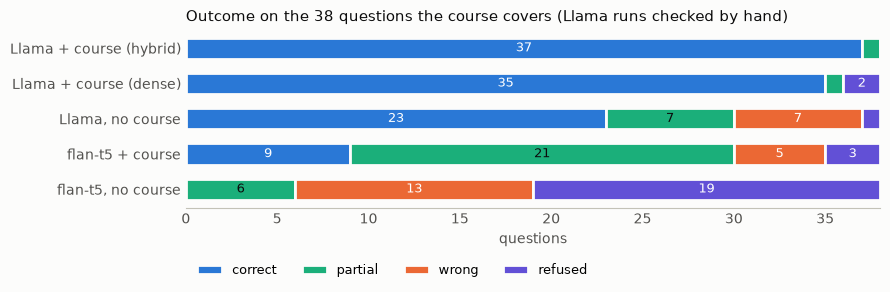

outcome,correct,partial,wrong,refused
system,,,,
"flan-t5, no course",0,6,13,19
flan-t5 + course,9,21,5,3
"Llama, no course",23,7,7,1
Llama + course (dense),35,1,0,2
Llama + course (hybrid),37,1,0,0


In [3]:
def outcome(r):
    if r.type == "out_of_scope":
        return None
    if r.abstained:
        return "refused"
    if r.hand:
        return r.hand
    if r.ok:
        return "correct"
    return "partial" if r.judge2_score in (1, 2) else "wrong"

df["outcome"] = df.apply(outcome, axis=1)
order = ["correct", "partial", "wrong", "refused"]
counts = (df[df.outcome.notna()].groupby(["system", "outcome"]).size().unstack(fill_value=0)
          .reindex(columns=order, fill_value=0).loc[list(RUNS.values())[::-1]])

# categorical slots from the dataviz reference palette; this stacking order passes the CVD and
# normal-vision separation checks (validate_palette.js). Counts are printed on the bars.
COLORS = {"correct": "#2a78d6", "partial": "#1baf7a", "wrong": "#eb6834", "refused": "#6250d6"}
fig, ax = plt.subplots(figsize=(9, 3.4))
left = pd.Series(0, index=counts.index)
for o in order:
    ax.barh(counts.index, counts[o], left=left, color=COLORS[o], label=o, height=0.6, edgecolor="#fcfcfb", linewidth=2)
    for y, (v, l) in enumerate(zip(counts[o], left)):
        if v >= 2:
            ax.text(l + v / 2, y, str(v), ha="center", va="center", fontsize=9, color="#0b0b0b" if o == "partial" else "#ffffff")
    left += counts[o]
ax.set_title("Outcome on the 38 questions the course covers (Llama runs checked by hand)", loc="left", fontsize=11, color="#0b0b0b")
ax.set_xlim(0, 38); ax.set_xlabel("questions", color="#52514e")
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7"); ax.tick_params(colors="#52514e", length=0)
ax.legend(ncol=4, frameon=False, loc="lower left", bbox_to_anchor=(0, -0.45), fontsize=9)
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
plt.tight_layout()
fig.savefig(PROJECT_ROOT / "docs/figures/outcomes.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()
counts[order]

**Reading it**
- **The course material is what makes the assistant both correct and honest.** With the same Llama model, hand-checked correctness rises from **61% to 92–97%**.
- **Llama + course answers cite their sources (all but one dense answer, which lost its citation marker), and the cited lecture is right 97–100% of the time.** The no-RAG chatbot cannot cite anything.
- **The no-RAG chatbot refuses the one question only the course can answer** (the MIT/Stanford study numbers) and confidently answers almost everything else, including topics the course never covers.
- **flan-t5 (the class RAG model) is far too small for this task.** With the course its automatic score goes from 0% to 24%, so RAG helps even a tiny model, but its answers are a few words long and almost never cite. Without the course it refuses half the covered questions.

## 2. Saying "not covered"

The proposal's other promise. The near-miss questions are the hard part: a model that *knows* about PPO or FID will happily answer, even though the course never covers them.

In [4]:
oos = df[df.type == "out_of_scope"].pivot(index="id", columns="system", values="abstained")[list(RUNS.values())]
oos.insert(0, "question", [questions[i]["question"] for i in oos.index])
oos.insert(1, "kind", [questions[i]["source"].split(" ")[0].rstrip(":") for i in oos.index])
oos.replace({True: "✓ not covered", False: "✗ answered"})

system,question,kind,Llama + course (hybrid),Llama + course (dense),"Llama, no course",flan-t5 + course,"flan-t5, no course"
id,,,,,,,
q39,What is label smoothing and why does it help when training a classifier?,near-miss,✓ not covered,✓ not covered,✗ answered,✓ not covered,✗ answered
q40,How does PPO's clipped objective keep policy updates stable?,near-miss,✓ not covered,✓ not covered,✗ answered,✓ not covered,✗ answered
q41,What is the codebook in a VQ-VAE?,near-miss,✓ not covered,✓ not covered,✗ answered,✗ answered,✗ answered
q42,How does Stable Diffusion run diffusion in a VAE's latent space?,near-miss,✓ not covered,✗ answered,✗ answered,✗ answered,✓ not covered
q43,How do mixture-of-experts layers route tokens to experts?,near-miss,✓ not covered,✓ not covered,✗ answered,✓ not covered,✓ not covered
q44,How is the FID score used to evaluate GAN image quality?,near-miss,✓ not covered,✓ not covered,✗ answered,✗ answered,✓ not covered
q45,What is the difference between L1 and L2 regularization?,near-miss,✓ not covered,✓ not covered,✗ answered,✓ not covered,✓ not covered
q46,How does Direct Preference Optimization (DPO) differ from RLHF?,near-miss,✓ not covered,✓ not covered,✗ answered,✓ not covered,✓ not covered
q47,How does GRPO compute advantages in DeepSeek's training?,near-miss,✓ not covered,✓ not covered,✓ not covered,✗ answered,✓ not covered


- **Without the course, Llama answers 8 of the 10 near-miss and trap questions.** It does know these topics, but a student asking a *course* assistant would wrongly believe they were taught.
- **With the course, it declines all of them (hybrid) or all but Stable Diffusion (dense).** That answer is analysed in section 8.
- flan-t5's "refusals" are partly just failures to answer anything, as its 50% false-refusal rate on covered questions shows.

## 3. Keyword vs paraphrased questions, and retrieval

In [5]:
ans = df[df.type != "out_of_scope"]
(ans.groupby(["system", "type"]).ok.mean().unstack().loc[list(RUNS.values())]
    .rename(columns={"keyword": "uses course term (30)", "paraphrase": "paraphrased (8)"}).round(2))

type,uses course term (30),paraphrased (8)
system,,
Llama + course (hybrid),0.97,0.88
Llama + course (dense),0.77,0.88
"Llama, no course",0.40,0.75
flan-t5 + course,0.30,0.00
"flan-t5, no course",0.00,0.00


In [6]:
from study_assistant.retrieval import load_chunks, build_retriever, Embedder
from study_assistant.retrieval_eval import evaluate as eval_retrieval, summarize as summarize_retrieval
qs = [{"id": q["id"], "query": q["question"], "gold_lectures": q["gold_lectures"], "gold_files": q["gold_files"],
       "out_of_scope": q["type"] == "out_of_scope"} for q in questions.values()]
chunks, emb = load_chunks(), Embedder()
ret = pd.concat([eval_retrieval(build_retriever(m, chunks, emb), qs) for m in ["tfidf", "bm25", "dense", "hybrid"]])
ret["type"] = ret.id.map(lambda i: questions[i]["type"])
print("Retrieval only, all 38 answerable questions"); display(summarize_retrieval(ret))
print("Paraphrased questions (8)"); display(summarize_retrieval(ret[ret.type == "paraphrase"]))

Retrieval only, all 38 answerable questions


,hit@1,hit@3,hit@5,MRR@10
tfidf,0.921,1.0,1.0,0.952
bm25,0.947,1.0,1.0,0.974
dense,0.921,1.0,1.0,0.961
hybrid,0.974,1.0,1.0,0.987


Paraphrased questions (8)


,hit@1,hit@3,hit@5,MRR@10
tfidf,0.750,1.0,1.0,0.833
bm25,0.750,1.0,1.0,0.875
dense,1.000,1.0,1.0,1.000
hybrid,0.875,1.0,1.0,0.938


**Retrieval is not the bottleneck on this set.** Inside the assistant, both retrievers put the right lecture (or lab) in the top 3 passages for all 38 questions.

These paraphrases turned out *easier* than the deliberately obscure development questions in notebook 02. A harder paraphrase set would separate the methods more. So the remaining errors come from the *answering* step, analysed below.

## 4. Can we trust the grader? (no, not on its own)

We used LLM-as-judge from the class (`llm_as_judge_solution.ipynb`) with Llama 3.1 8B. Auditing its scores found two opposite problems.

**Judge v1** saw only our short reference answer. **It marked down correct course details that the reference happened to leave out.** We checked each one against the course text:

In [7]:
import re
from study_assistant.ingest import load_documents
docs = load_documents()
claims = {  # detail in a RAG answer that v1 called wrong/unrelated -> is it in the course?
    "q23: denoiser takes noise_rates and signal_rates": ("Module_7_Practical_2", r"def denoise\(self, noisy_images, noise_rates, signal_rates"),
    "q27: causal mask is lower-triangular": ("Module_8_Practical_GPT", r"lower[- ]triangular"),
    "q35: LLM-as-judge tier = rubric, safety, failure tags": ("llm_evals", r"rubric, safety, failure tags"),
    "q36: 'conditional edges' in LangGraph": ("Agentic_workflow", r"conditional edge"),
    "q22: MLE-inspired contrastive divergence": ("Module 8 - Energy", r"Maximum Likelihood.*contrastive divergence"),
    "q09: environmental impact as an ethical concern": ("Module 3 - Applications", r"environmental"),
}
pd.DataFrame([(c, any(re.search(f, d.source_file) and re.search(t, " ".join(d.text.split()), re.I | re.S) for d in docs))
              for c, (f, t) in claims.items()], columns=["detail judge v1 penalised", "found in course text"])

,detail judge v1 penalised,found in course text
0,q23: denoiser takes noise_rates and signal_rates,True
1,q27: causal mask is lower-triangular,True
2,"q35: LLM-as-judge tier = rubric, safety, failure tags",True
3,q36: 'conditional edges' in LangGraph,True
4,q22: MLE-inspired contrastive divergence,True
5,q09: environmental impact as an ethical concern,True


**Judge v2** therefore also sees the 3 most relevant excerpts of the right lecture, the same for every system. That fixed those cases.

But **v2 is too lenient on very short answers**: it gives full marks to answers of a word or two, as if grading the excerpts rather than the answer. The key-fact check (deterministic) catches exactly these:

In [8]:
judged = df[df.judge2_score.notna()]
print("judge v2 score vs key-fact recall (all systems):")
display(pd.crosstab(judged.judge2_score.astype(int), (judged.key_fact_recall >= 0.5).map({True: "≥ half key facts", False: "< half"})))
display(judged[(judged.judge2_score == 2) & (judged.key_fact_recall == 0)][["system", "id", "answer", "judge2_reason"]])

judge v2 score vs key-fact recall (all systems):


key_fact_recall,< half,≥ half key facts
judge2_score,,
0,22,1
1,5,19
2,25,93


,system,id,answer,judge2_reason
6,"flan-t5, no course",q07,zero-shot,"The assistant's answer accurately identifies zero-shot prompting as directly asking without examples, matc..."
9,"flan-t5, no course",q10,squeeze,"The assistant's answer accurately states that squeeze removes dimensions of size 1, matching the course ma..."
21,"flan-t5, no course",q22,loss function,"The assistant's answer directly states the loss function used to train an energy-based model, which is a f..."
22,"flan-t5, no course",q23,a neural network,The assistant's answer correctly identifies the network architecture used as the denoiser in diffusion mod...
37,"flan-t5, no course",q38,metric,"The assistant's answer directly matches the reference answer, correctly identifying the metric used to mea..."
70,"Llama, no course",q21,"Energy-based models, such as the Restricted Boltzmann Machine (RBM), output an energy value instead of a p...",The assistant's answer accurately explains why energy-based models output an energy value instead of a pro...
74,"Llama, no course",q25,"In the context of self-attention mechanisms, positional encoding is used to inject information about the p...",The assistant's answer accurately summarizes the advantages of sinusoidal positional encoding over adding ...
77,"Llama, no course",q28,Adding attention to an image-generating GAN (Generative Adversarial Network) allows the model to focus on ...,"The assistant's answer accurately summarizes the main point from the course materials, explaining how atte..."
105,flan-t5 + course,q06,[1],The assistant's answer directly references Bayes' theorem as the rule for updating beliefs from noisy sens...
108,flan-t5 + course,q09,potential challenges and future considerations,"The assistant's answer accurately lists the main ethical concerns discussed in the course, including bias,..."


**So the main metric requires both**: the grader says correct (meaning) *and* at least half the key facts are present (substance). We designed this metric after seeing the first results, so it is not pre-registered; v1 and v2 scores are reported in section 9 for transparency.

The grader is also **inconsistent**: the hybrid and dense answers to q02 say nearly the same thing, yet scored 2 and 1. That is why section 5 checks the answers by hand.

## 5. Hand check, confidence intervals and significance

We re-read, against the reference and the lecture, **every answer the main metric marked as not correct** in every Llama run, and all answers it marked correct for the main system and the no-course baseline (none of those were overturned). Verdicts and reasons are in `eval/hand_labels.json`. This is the developers' judgement, not a blind review.

Where the hand check disagrees with the automatic metric:

In [9]:
rows = [(NAMES[r], i, questions[i]["question"][:70], "correct" if ok else "not correct", v, why)
        for r, labels in hand.items() if r in NAMES
        for i, (v, why) in labels.items()
        for ok in [bool(all_df[(all_df.run == r) & (all_df.id == i)].ok.iloc[0])]]
checked = pd.DataFrame(rows, columns=["system", "id", "question", "main metric", "by hand", "why"])
checked[(checked["main metric"] == "correct") != (checked["by hand"] == "correct")]

,system,id,question,main metric,by hand,why
1,Llama + course (hybrid),q29,"In the GPT practical, how does top-k sampling change text generation?",not correct,correct,'truncates the long tail before sampling' = keep only the k most likely; key-fact wording too strict
2,Llama + course (dense),q02,What is the difference between intrinsic and extrinsic hallucinations?,not correct,correct,same definitions as the hybrid answer (judge v2 gave that one 2)
5,Llama + course (dense),q20,What is the core idea of a normalizing flow?,not correct,correct,change of variables to a Gaussian with a neural network: the core idea asked for
6,Llama + course (dense),q27,What is a causal attention mask and why does GPT need one?,not correct,correct,-inf before softmax blocks future positions; judge v2 complaint is wrong
7,Llama + course (dense),q29,"In the GPT practical, how does top-k sampling change text generation?",not correct,correct,"same content as hybrid q29 (citation marker lost: 'According to passage ,')"
9,Llama + course (dense),q35,What are the four tiers of the LLM evaluation harness from the evals l,not correct,correct,lists all four tiers exactly; judge v2 complaint is wrong
13,support check: strict,q29,"In the GPT practical, how does top-k sampling change text generation?",not correct,correct,same answer as hybrid q29
17,"Llama, no course",q05,What are the limitations of sparse document-term embeddings?,not correct,correct,high cost and no semantic relationships; judge too harsh
19,"Llama, no course",q07,"What is the difference between zero-shot, one-shot and few-shot prompt",not correct,correct,no / one / a few examples; key-fact wording too strict
21,"Llama, no course",q09,What ethical concerns about generative AI does the course discuss?,not correct,correct,"bias, misinformation, intellectual property"


Most disagreements are correct answers whose wording the key-fact lists didn't anticipate, or grader noise. **The hand check raises every Llama system's score, by 1 question (hybrid) to 5 (dense, no course); the ranking stays the same.**

With 38 + 12 questions every rate is uncertain by several points, so `eval/analysis.py` reports 95% Wilson intervals. It compares each system with the main one by an **exact McNemar test**: both answered the same questions, so only the questions where they disagree carry information.

In [10]:
spec = importlib.util.spec_from_file_location("analysis", PROJECT_ROOT / "eval/analysis.py")
analysis = importlib.util.module_from_spec(spec); spec.loader.exec_module(analysis)
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    analysis.main()
display(Markdown(buf.getvalue()))

Answerable questions correct (auto = main metric; hand = after re-reading, eval/hand_labels.json),
and not-covered questions abstained. 95% Wilson intervals in brackets.

| configuration | correct (auto) | correct (hand) | not covered → abstained | all 50 handled (hand) |
|---|---|---|---|---|
| Llama + course, hybrid (main) | 36/38 = 95% [83%–99%] | 37/38 = 97% [87%–100%] | 12/12 = 100% [76%–100%] | 49/50 = 98% [90%–100%] |
| Llama + course, dense | 30/38 = 79% [64%–89%] | 35/38 = 92% [79%–97%] | 11/12 = 92% [65%–99%] | 46/50 = 92% [81%–97%] |
| relevance check off | 37/38 = 97% [87%–100%] | 37/38 = 97% [87%–100%] | 12/12 = 100% [76%–100%] | 49/50 = 98% [90%–100%] |
| support check: strict | 35/38 = 92% [79%–97%] | 36/38 = 95% [83%–99%] | 12/12 = 100% [76%–100%] | 48/50 = 96% [87%–99%] |
| support check: concept | 36/38 = 95% [83%–99%] | 37/38 = 97% [87%–100%] | 12/12 = 100% [76%–100%] | 49/50 = 98% [90%–100%] |
| Llama, no course | 18/38 = 47% [32%–63%] | 23/38 = 61% [45%–74%] | 4/12 = 33% [14%–61%] | 27/50 = 54% [40%–67%] |
| flan-t5 + course | 9/38 = 24% [13%–39%] | not re-checked | 8/12 = 67% [39%–86%] | — |
| flan-t5, no course | 0/38 = 0% [0%–9%] | not re-checked | 6/12 = 50% [25%–75%] | — |

Paired comparisons with the main system (exact McNemar test, hand labels; all 50 questions:
an answerable question counts if answered correctly, a not-covered one if the system abstained).

| main vs | main right, other wrong | main wrong, other right | p |
|---|---|---|---|
| Llama, no course | 23 | 1 | 2.98e-06 |
| Llama + course, dense | 4 | 1 | 0.375 |
| relevance check off | 1 | 1 | 1 |
| support check: strict | 1 | 0 | 1 |
| support check: concept | 0 | 0 | 1 |


- **Course vs no course is the one difference this test set clearly establishes:** they disagree on 24 questions and the assistant wins 23.
- **Dense vs hybrid is not resolved** (4 vs 1 disagreements in hybrid's favour, p = 0.38). Hybrid is the default because it never refused a covered question, but it was chosen on this set, so its numbers are slightly optimistic; dense is the unselected baseline.
- The ablations are discussed next.

## 6. Ablation: does the LLM relevance check help?

The assistant has two ways to say "not covered": an LLM **relevance check** on the retrieved passages (after a similarity floor that drops obvious off-topic questions), and the **answer prompt**, which tells the model to reply with the "not covered" sentence if the passages are insufficient. Which one actually declines?

In [11]:
ab = all_df[all_df.abstained & all_df.run.str.startswith("rag__ollama")].copy()
ab["declined by"] = ab.abstain_reason.str.replace(r"\(best similarity.*", "", regex=True).str.strip()
ab.groupby(["system", "declined by"]).size().unstack(fill_value=0)

declined by,off-topic,support check: answer not supported by the passages,the model found the passages insufficient
system,,,
Llama + course (dense),2,0,11
Llama + course (hybrid),2,0,10
relevance check off,2,0,10
support check: concept,2,0,10
support check: strict,2,1,10


**The relevance check never declined a single question,** in any run: it always accepted at least one passage. The 2 off-topic questions were caught by the similarity floor, and everything else by the answer prompt.

Turning the check off (`--grading none`):

In [12]:
ablation = summarize(all_df[all_df.run.isin(["rag__ollama__llama3.1-8b__hybrid", "rag__ollama__llama3.1-8b__hybrid__nograde"])]).rename(index=NAMES)
ablation[["correct (main)", "false refusals", "not covered → abstained", "near-miss → abstained", "sec / question"]]

,correct (main),false refusals,not covered → abstained,near-miss → abstained,sec / question
Llama + course (hybrid),0.947,0.0,1.0,1.0,13.738
relevance check off,0.974,0.0,1.0,1.0,10.344


Same abstentions, and correctness within one question each way (hybrid misses q19, the ablation misses q15; see section 5). The check costs one extra LLM call per question for no measurable benefit with an 8B model. It stays in the code because a stronger model might use it better, but this is a negative result worth reporting.

## 7. Ablation: the support check (Step 6)

The support check (Section 7 of the report) adds a second LLM call after answering and declines if it fails. **strict** asks whether the answer's content is stated in the passages; **concept** asks whether the passages discuss the specific thing asked about. On hand-labelled *development* answers (`eval/support_check/dev_labels.json`), concept rejected the 3 wrong answers and no correct ones, while strict rejected 2 correct answers and 1 wrong one. That is how concept was chosen, before running it here.

On the evaluation set there is little left to catch: the main system already declines all 12 not-covered questions. What each variant changed:

In [13]:
for run in ["rag__ollama__llama3.1-8b__hybrid__verify", "rag__ollama__llama3.1-8b__hybrid__verify-concept"]:
    g = all_df[all_df.run == run].set_index("id")
    base = all_df[all_df.run == "rag__ollama__llama3.1-8b__hybrid"].set_index("id")
    removed = g[g.abstain_reason.str.startswith("support check")]
    print(f"=== {NAMES[run]}: {len(removed)} answer(s) replaced by 'not covered'")
    for i in removed.index:
        verdict = base.loc[i, "hand"] or ("correct" if base.loc[i, "ok"] else "?")
        print(f"  {i} {questions[i]['question'][:70]}  (the main system's answer was: {verdict})")
display(summarize(all_df[all_df.run.isin(["rag__ollama__llama3.1-8b__hybrid", *list(ABLATIONS)[1:]])]).rename(index=NAMES)
        [["correct (main)", "false refusals", "not covered → abstained", "sec / question"]])

=== support check: strict: 1 answer(s) replaced by 'not covered'
  q02 What is the difference between intrinsic and extrinsic hallucinations?  (the main system's answer was: correct)
=== support check: concept: 0 answer(s) replaced by 'not covered'


,correct (main),false refusals,not covered → abstained,sec / question
Llama + course (hybrid),0.947,0.000,1.0,13.738
support check: concept,0.947,0.000,1.0,17.933
support check: strict,0.921,0.026,1.0,17.827


Strict rejected one answer the hand check counts as correct (q02); concept changed nothing, at about 4 s extra per answer. So the check stays **off by default** and is available as `chat --verify` (concept). It should matter for answers like dense's Stable Diffusion one (section 8), which the hybrid system did not produce.

## 8. What goes wrong (Llama + course)

In [14]:
for name in ["Llama + course (hybrid)", "Llama + course (dense)"]:
    rag = df[df.system == name].set_index("id")
    print(f"=== {name}: covered questions not correct by hand")
    for i, r in rag[(rag.type != "out_of_scope") & (rag.outcome != "correct")].iterrows():
        print(f"  {i} {questions[i]['question'][:80]}  ->  {r.outcome}")
    print(f"=== {name}: not-covered questions it answered anyway")
    for i, r in rag[(rag.type == "out_of_scope") & ~rag.abstained].iterrows():
        print(f"  {i} {questions[i]['question']}\n     cited: " + "; ".join(s["label"][:60] for s in r.sources))
    print()

=== Llama + course (hybrid): covered questions not correct by hand
  q19 How can a GAN be made to generate an image of a specific class, like a particula  ->  partial
=== Llama + course (hybrid): not-covered questions it answered anyway

=== Llama + course (dense): covered questions not correct by hand
  q11 What is the difference between view and reshape in PyTorch?  ->  partial
  q17 Why does WGAN-GP add a gradient penalty to the critic loss?  ->  refused
  q30 Can the moves an RL agent chooses from be smooth amounts rather than a fixed lis  ->  refused
=== Llama + course (dense): not-covered questions it answered anyway
  q42 How does Stable Diffusion run diffusion in a VAE's latent space?
     cited: Lecture 5 · Module 4: Practical - Variational Autoencoders, ; Lecture 8 · Module 7: Practical 2 - Diffusion Methods, cells



In [15]:
r = df[(df.system == "Llama + course (dense)") & (df.id == "q42")].iloc[0]
print(r.answer)

Stable Diffusion runs diffusion in a VAE's latent space by first sampling from the normal distribution output by the encoder, which is the mean and log variance of a normal distribution [1]. This sampled latent variable is then used as input to the diffusion process, which adds noise through a series of steps and has a neural network learn the inverse process [2].


**The most dangerous failure: a confident answer with citations that don't support it.** For *Stable Diffusion* (dense), the relevance check accepted the VAE practical and the diffusion practical. Llama then wrote an answer from its own knowledge and attached citations to those passages. Citations look trustworthy, so this is worse than an uncited answer. (Before the audit the same happened for *vanishing gradients*, which turned out to be half covered by the course; we replaced that question.)

Other errors are smaller:
- generic answers that miss the course's specific point (hybrid: q19, conditional GANs without the one-hot labels)
- subtly wrong details (dense: q11)
- over-cautious refusals when the material *was* retrieved (dense: q17, q30)

## 9. All metrics, all systems

In [16]:
summarize(all_df).rename(index=NAMES).loc[list(NAMES.values())].T

,Llama + course (hybrid),Llama + course (dense),"Llama, no course",flan-t5 + course,"flan-t5, no course",relevance check off,support check: strict,support check: concept
answerable,38.000,38.000,38.000,38.000,38.000,38.000,38.000,38.000
correct (main),0.947,0.789,0.474,0.237,0.000,0.974,0.921,0.947
correct (judge v2),1.000,0.842,0.579,0.553,0.132,0.974,0.974,1.000
correct or partial (v2),1.000,0.947,0.842,0.789,0.158,0.974,0.974,1.000
correct (judge v1),0.816,0.711,0.447,0.158,0.000,0.816,0.789,0.816
key-fact recall,0.877,0.864,0.616,0.301,0.000,0.904,0.851,0.877
false refusals,0.000,0.053,0.026,0.079,0.500,0.000,0.026,0.000
not covered → abstained,1.000,0.917,0.333,0.667,0.500,1.000,1.000,1.000
near-miss → abstained,1.000,0.900,0.200,0.600,0.600,1.000,1.000,1.000
answers with no citation,0.000,0.028,NaN,0.914,NaN,0.000,0.000,0.000


## Summary

| Question from the proposal | Answer (Llama 3.1 8B + course, hybrid) |
|---|---|
| How often does it answer correctly? | **97%** of covered questions by hand (37/38; 95% CI 87–100%). No course: 61% |
| Does it cite the right source? | **97%** of answers cite the right lecture; every answer has a citation |
| Does it admit when it doesn't know? | **100%** of not-covered questions (12/12; no course: 33%), including all 10 near-misses and the trap (no course: 20%) |
| Better than a chatbot without the materials? | Yes, clearly (49 vs 27 of 50 handled correctly, p < 0.001); the cost is about 2× the time per question (14 s vs 7 s locally) |

**Limitations**
- **Small test set.** 38 + 12 questions, so one question is 2.6 / 8 percentage points, and only large differences are statistically clear.
- **The grader is Llama 3.1 8B, the same model as the answerer.** It is noisy in both directions, hence the combined metric and the hand check.
- **Post-hoc choices.** The main metric was designed, and hybrid selected, after seeing results on this set.
- **Easy paraphrases.** The paraphrased questions turned out easier than the development ones.
- **Not independently reviewed.** The questions and reference answers were drafted with AI assistance and checked automatically; a second human reviewer would strengthen them.